# Libraries

```markdown
- langchain_ollama
  - ChatOllama
- langchain.messages
  - SystemMessage
  - HumanMessage
  - AIMessage
- langchain_core.messages.utils
  - count_tokens_approximately
- langchain_core.prompts
  - PromptTemplate
  - ChatPromptTemplate
  - FewShotPromptWithTemplates
  - structured.StructuredPrompt
- langchain_core.load
  - dumps
  - loads

- langchain.agents
  - create_agent
  - AgentState
- langchain.agents.structured_output
  - ProviderStrategy
- langchain.agents.middleware
  - after_model
  - SummarizationMiddleware

- langgraph.graph
  - StateGraph
  - MessagesState
  - START, END
- langgraph.runtime
  - Runtime
- langgraph.checkpoint.memory
  - InMemorySaver
- langgraph.types
  - Command
  - Send


```

# Setup

In [1]:
from pprint import pprint
from pathlib import Path
from dotenv import dotenv_values
from pydantic import BaseModel


cfg = dotenv_values()

SEED = cfg['SEED']

# 1. Prompt Template

## 1.1. Prompt

In [2]:
from langchain_core.prompts import PromptTemplate

template = PromptTemplate.from_template(
    'User name is {name}',
)

prompt = template.invoke({
    'name': 'aruwad'
})

## 1.2. Chat Prompt

In [3]:
from langchain_core.prompts import ChatPromptTemplate

template = ChatPromptTemplate.from_messages([
    ('system', 'You are a helpful assistant.'),
    ('human', '{query}'),
    ('placeholder', '{name}'),   # optional
])

prompt = template.invoke({
    'query': 'what is your name?',
    'age': ['20'],
})

## 1.3. Few-Shot Prompt

In [4]:
from langchain_core.prompts import FewShotPromptWithTemplates

template = FewShotPromptWithTemplates(
    examples=[
        {'word': 'high', 'opposite': 'low'},
        {'word': 'big', 'opposite': 'small'},
    ],
    example_prompt=PromptTemplate.from_template(
        'word: {word}, opposite: {opposite}'
    ),
    prefix=PromptTemplate.from_template(
        'You are a helpful assistant.'
    ),
    suffix=PromptTemplate.from_template(
        'word: {word}, opposite: '
    ),
    input_variables=['word'],
)

prompt = template.invoke({
    'word': 'Large',
})

## 1.4. Structured Prompt

In [5]:
from langchain_core.prompts.structured import StructuredPrompt
from langchain_ollama import ChatOllama

class Response(BaseModel):
    """Response answer with reason."""
    answer: str
    reason: str

template_structured = StructuredPrompt(     # can't .model_dump_json()
    [
        ('system', 'Answer with reason.'),
        ('human', '{query}'),
    ],
    Response,
)

chat = ChatOllama(model='qwen3:0.6b')
chatbot = template_structured | chat
response = chatbot.invoke('What is 1 + 1?')

print(response.answer)
print(response.reason)

C:\Users\yana\AppData\Local\Temp\ipykernel_17356\2387314983.py:9: LangChainBetaWarning: The class `StructuredPrompt` is in beta. It is actively being worked on, so the API may change.
  template_structured = StructuredPrompt(     # can't .model_dump_json()


1 + 1 = 2
This is a basic arithmetic problem. Adding 1 and 1 gives 2. There's no trick or hidden complexity here.


## 1.5. Save & Load

In [6]:
from langchain_core.load import dumps, loads

path = Path('../tmp/prompt_template.json')
path.write_text(dumps(template))
template = loads(
    path.read_text(),
    allowed_objects='all',
)

C:\Users\yana\AppData\Local\Temp\ipykernel_17356\178959745.py:5: LangChainBetaWarning: The function `loads` is in beta. It is actively being worked on, so the API may change.
  template = loads(


# 2. Chat Model

## 2.1. Basic

In [7]:
from langchain_ollama import ChatOllama

chat = ChatOllama(
    model='qwen3:1.7b',
    reasoning=True,
    temperature=0.6,
    top_k=5,
    top_p=0.9,
    num_ctx=1_024,
    num_predict=256,
    seed=SEED,
)

resp = chat.invoke('What is 1 + 1?')
print(resp.content)
print(resp.additional_kwargs['reasoning_content'])


Okay, the user is asking "What is 1 + 1?" at first glance, it seems like a simple arithmetic question. But I need to make sure I understand the context. Maybe they're testing if I can recognize a basic math problem or if there's a trick involved. Let me think.

In standard arithmetic, 1 plus 1 is 2. But sometimes, people might use different interpretations. For example, in some contexts, especially in programming or certain mathematical fields, there could be different rules. However, the question doesn't mention any specific context, so I should stick to the standard mathematical definition.

Wait, maybe the user is trying to see if I can recognize a common mistake. Like, someone might think it's 1 + 1 = 2, but maybe they're confused about something else. But no, the question is straightforward. The answer is definitely 2. 

Alternatively, could there be a trick here? For instance, in some puzzles or riddles, 1 + 1 might be presented in a way that's not immediately obvious. But witho

## 2.2. Streaming

In [8]:
from time import sleep

resp = chat.stream('What is 1 + 1?')

for chunk in resp:
    if chunk.content != '':
        print(chunk.content, end='', flush=True)
        sleep(0.1)

## 2.3. Save & Load

In [9]:
path = Path('../tmp/chat_config.json')
path.write_text(chat.model_dump_json())
chat = ChatOllama.model_validate_json(path.read_text())

# 3. Agent

## 3.1. Response Format

In [10]:
from langchain.agents import create_agent
from langchain.agents.structured_output import ProviderStrategy
from langchain.messages import SystemMessage, HumanMessage

agent = create_agent(
    model=chat,
    system_prompt=SystemMessage('You are a helpful assistant.'),
    response_format=ProviderStrategy(Response),     # avoid tool cooling for explicit structure
)

resp = agent.invoke(
    input={
        'messages': [HumanMessage('What is 1 + 1?')],
    }
)

for msg in resp['messages']:
    print(msg)

content='What is 1 + 1?' additional_kwargs={} response_metadata={} id='5a4fa215-437a-497a-9a1d-8c2d80c2586f'
content='{ "answer": "1 + 1 equals 2.","reason": "This is a basic arithmetic operation where 1 added to another 1 results in 2." }' additional_kwargs={'reasoning_content': 'Okay, the user is asking "What is 1 + 1?" Let me think. Well, 1 plus 1 is a basic arithmetic operation. The answer should be 2. But I need to make sure I\'m not missing anything here. Sometimes people might confuse it with other operations, but no, addition is straightforward. Just 1 added to another 1. Yeah, the result is definitely 2. I should state that clearly. Maybe add a simple explanation to confirm it\'s basic math. Alright, keep it simple and direct.\n'} response_metadata={'model': 'qwen3:1.7b', 'created_at': '2026-11-09T04:03:13.0761949Z', 'done': True, 'done_reason': 'stop', 'total_duration': 433532800, 'load_duration': 7282100, 'prompt_eval_count': 29, 'prompt_eval_duration': 11346000, 'eval_count

## 3.2. Context

In [11]:
from langchain.agents import AgentState
from langchain.agents.middleware import after_model
from langgraph.runtime import Runtime

class CallCount(AgentState):
    """Agent state."""
    call_count: int

class UserName(BaseModel):
    """Runtime context."""
    user_name: str

@after_model(state_schema=CallCount)
def save_answer(state: CallCount, runtime: Runtime):
    user_name = runtime.context

    cnt = state['call_count'] + 1
    return {'call_count': cnt}


agent = create_agent(
    model=chat,
    system_prompt=SystemMessage('You are a helpful assistant.'),
    state_schema=CallCount,
    context_schema=UserName,
    middleware=[save_answer],
)

resp = agent.invoke(
    input={
        'messages': [HumanMessage('What is 1 + 1?')],
        'call_count': 0,
    },
    context=UserName(user_name='aruwad'),
)

resp['call_count']

1

## 3.3. Checkpointer

In [12]:
from langgraph.checkpoint.memory import InMemorySaver

checkpointer = InMemorySaver()

agent = create_agent(
    model=chat,
    system_prompt=SystemMessage('You are a helpful assistant.'),
    checkpointer=checkpointer,
)

config = {'configurable': {'thread_id': 'user-1'}}

resp = agent.invoke({'messages': ['My name is yana.']}, config=config)
resp = agent.invoke({'messages': ['What is my name?']}, config=config)

for msg in resp['messages']:
    msg.pretty_print()

================================ Human Message =================================

My name is yana.
================================== Ai Message ==================================

Hello, Yana! How can I assist you today? 😊
================================ Human Message =================================

What is my name?
================================== Ai Message ==================================


## 3.4. Tool

In [13]:
from langchain.tools import tool, ToolRuntime
from langchain.messages import ToolMessage
from langchain.agents import AgentState
from langchain.agents.middleware import (
    ToolErrorMiddleware,
    ToolCallRequest,
    ToolCallLimitMiddleware,
)
from langgraph.types import Command

class AddResult(AgentState):
    result: int

@tool
def add_ints(x: int, y: int, runtime: ToolRuntime) -> Command:
    """Add two integers and update the state."""
    if x < 0 or y < 0:
        raise ValueError("x and y must be >= 0!")

    result = x + y
    messages = [
        ToolMessage(
            str(x + y),
            tool_call_id=runtime.tool_call_id,
        ),
    ]

    return Command(
        update={'result': result, 'messages': messages},
    )

def on_error(exception: Exception, request: ToolCallRequest) -> str | None:
    match exception:
        case ValueError():
            return f"Tool: {request.tool_call['name']}, Error: {str(ValueError.__name__)}, Reason: x and y must be >= 0!"
        case _:
            return f"Tool: {request.tool_call['name']}, Error: {type(exception).__name__}"

agent = create_agent(
    model=chat,
    system_prompt=SystemMessage('Use a tool to answer user question.'),
    state_schema=AddResult,
    tools=[add_ints],
    middleware=[
        ToolErrorMiddleware(
            on_error=on_error,
            tools=[add_ints],
        ),
        ToolCallLimitMiddleware(
            tool_name='add_ints',
            run_limit=3,
        )
    ]
)

resp = agent.invoke({
    'messages': ['What is 1 + 2?'],
    'result': 0,
})

for msg in resp['messages']:
    msg.pretty_print()

================================ Human Message =================================

What is 1 + 2?
================================== Ai Message ==================================
Tool Calls:
  add_ints (d884ff70-22ac-4ab2-8d5b-5ed58f9e85ec)
 Call ID: d884ff70-22ac-4ab2-8d5b-5ed58f9e85ec
  Args:
    x: 1
    y: 2
================================= Tool Message =================================
Name: add_ints

3
================================== Ai Message ==================================

The result of $1 + 2$ is $\boxed{3}$.


## 3.5. Visualize

                                      +-----------+                  
                                      | __start__ |                  
                                      +-----------+                  
                                            *                        
                                            *                        
                                            *                        
                                        +-------+                    
                                        | model |                    
                                     ***+-------+....                
                                 ****                ...             
                              ***                       ...          
                            **                             ....      
+-----------------------------------------------+              ..    
| ToolCallLimitMiddleware[add_ints].after_model |               .    
+-------------------

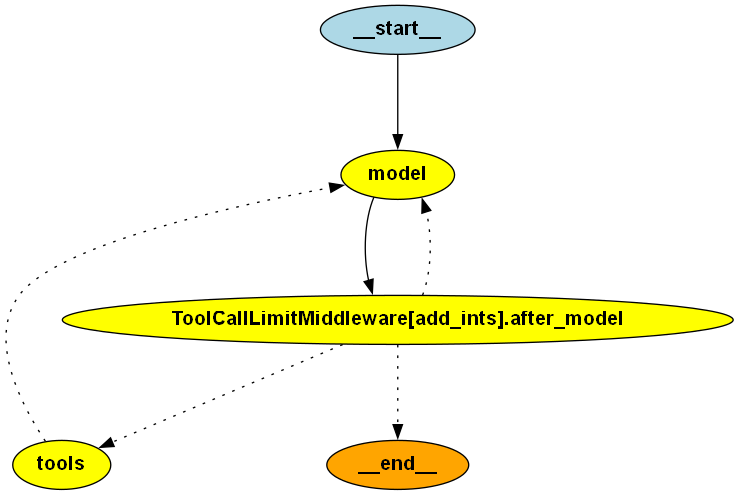

In [14]:
from IPython.display import Image

graph = agent.get_graph()

graph.print_ascii()

display(Image(agent.get_graph().draw_png()))

# 4. Graph

State:  StateSnapshot(values={'messages': [HumanMessage(content='What is 1 - 2?', additional_kwargs={}, response_metadata={}, id='eac24483-53aa-45d7-8d3f-d14b81bb428d')], 'x': 1, 'y': 2, 'op': '-', 'result': 1, 'op_history': []}, next=(), config={'configurable': {'thread_id': 'user-1', 'checkpoint_ns': '', 'checkpoint_id': '1f1dbf27-dcd1-6a55-8002-187bbe084838'}}, metadata={'source': 'loop', 'step': 2, 'parents': {}}, created_at='2026-11-09T04:03:16.435814+00:00', parent_config={'configurable': {'thread_id': 'user-1', 'checkpoint_ns': '', 'checkpoint_id': '1f1dbf27-dcd0-63b4-8001-06f148caab53'}}, tasks=(), interrupts=())
================================ Human Message =================================

What is 1 - 2?


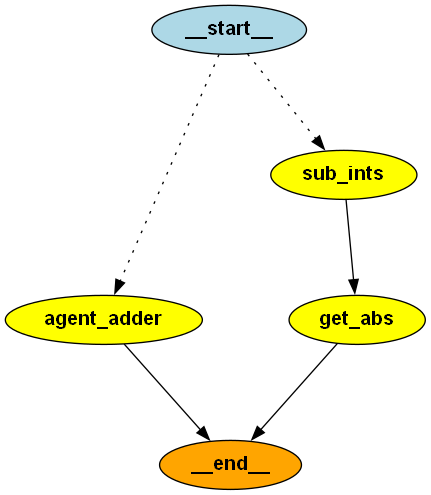

In [15]:
from typing import NotRequired, Annotated
from operator import add
from langchain_ollama import ChatOllama
from langchain.tools import tool, ToolRuntime
from langchain_core.messages import ToolMessage
from langgraph.types import Command, Send
from langchain.agents import create_agent
from langgraph.graph import StateGraph, MessagesState, START, END
from langgraph.checkpoint.memory import InMemorySaver
from IPython.display import Image


# 1. Chat & Tools & Agent
chat = ChatOllama(model='qwen3:1.7b')

@tool
def add_ints(x: int, y: int, runtime: ToolRuntime) -> Command:
    """Add two integers and update graph state."""
    result = x + y

    return Command(
        graph=Command.PARENT,
        update={
            'result': result,
            'op_history': ['+'],
            'messages': [
                runtime.state['messages'][-1],
                ToolMessage(
                    content=str(result),
                    tool_call_id=runtime.tool_call_id,
                ),
            ],
        },
    )

agent_adder = create_agent(
    model=chat,
    system_prompt=SystemMessage('You must use a tool for addition.'),
    tools=[add_ints],
)

# 2. Graph
class CalcState(MessagesState):
    x: int
    y: int
    op: str
    result: NotRequired[int]                 # optional
    op_history: Annotated[list[str], add]    # reducer: concatenate

def sub_ints(state: CalcState):
    return {'result': state['x'] - state['y']}

def get_abs(state: CalcState):
    return {'result': abs(state['result'])}

def controller(state: CalcState):
    if state['op'] == '+':
        return [
            Send('agent_adder', {'messages': state['messages']})
        ]
    else:
        return [
            Send('sub_ints', {'x': state['x'], 'y': state['y']})
        ]

builder = StateGraph(state_schema=CalcState)
builder.add_node('agent_adder', agent_adder)
builder.add_sequence([
    ('sub_ints', sub_ints),
    ('get_abs', get_abs),
])
builder.add_conditional_edges(
    START, controller, ['agent_adder', 'sub_ints'],
)
builder.add_edge('agent_adder', END)
builder.add_edge('get_abs', END)

graph = builder.compile(checkpointer=InMemorySaver())

# 3. Run
config = {'configurable': {'thread_id': 'user-1'}}
resp = graph.invoke(
    input={
        'messages': [HumanMessage('What is 1 - 2?')],
        'x': 1,
        'y': 2,
        'result': 0,
        'op': '-',
        'op_history': [],
    },
    config=config,
)

print('State: ', graph.get_state(config))

for msg in resp['messages']:
    msg.pretty_print()

# 4. Visualize
display(Image(graph.get_graph().draw_png()))

# 5. Memory

## 5.1. Summarization

In [26]:
from langchain.agents.middleware import SummarizationMiddleware
from langchain_core.messages.utils import count_tokens_approximately
from langchain.agents.middleware.summarization import DEFAULT_SUMMARY_PROMPT

summary_model = ChatOllama(model='qwen3:0.6b')

agent = create_agent(
    model=chat,
    middleware=[
        SummarizationMiddleware(
            model=summary_model,
            trigger=('tokens', 10_000),                     # conversation's n_total_tokens > 10_000 -> summarize
            keep=('tokens', 1_000),                         # preserve the last 1_000 tokens; 'messages' for last messages
            token_counter=count_tokens_approximately,       # approximate token counting
            summary_prompt=DEFAULT_SUMMARY_PROMPT,          # built-in summarization prompt
            trim_tokens_to_summarize=2_000,                 # keep last 2_000 tokens before summarization
        ),
    ],
)

## 5.2. Store

### 5.2.1. In-Memory

- Create & Store

In [ ]:
from langchain_ollama import ChatOllama, OllamaEmbeddings
from langchain.agents import create_agent
from langmem import (
    create_memory_store_manager,
    create_search_memory_tool,
)
from langgraph.store.memory import InMemoryStore


# 1. Memory Schemas
class Fact(BaseModel):
    """One concrete fact."""
    content: str


# 2. Store
store = InMemoryStore(
    index={
        "embed": OllamaEmbeddings(model='qwen3-embedding:0.6b'),
        "dims": 1024,
    },
)
namespace = ("structured_memory", "user-1", "fact")


# 3. Memory Manager
memory_manager_model = ChatOllama(
    model="qwen3:0.6b",
    reasoning=False,
)

memory_manager = create_memory_store_manager(
    memory_manager_model,
    schemas=[Fact],
    namespace=namespace,
    store=store,
    query_limit=5,
    enable_inserts=True,
    enable_deletes=False,
    instructions=(
        "Call the Fact tool for each explicit fact the user states"
        "about themselves, including their name."
    ),
)

search_tool = create_search_memory_tool(
    store=store,
    namespace=namespace,
)


# 4. Agent
chat = ChatOllama(
    model="qwen3:4b",
    reasoning=False,
)

agent = create_agent(
    model=chat,
    tools=[search_tool],
    system_prompt=(
        "You are a helpful assistant."
        "Use provided tool to retrieve memory and answer user question."
    ),
)


# 5. Invoke
history = "My name is yana."
changes = memory_manager.invoke({
    "messages": [{"role": "user", "content": history}]
})

query = "What is my name?"
resp = agent.invoke(
    input={
        "messages": [query]
    }
)

for msg in resp["messages"]:
    msg.pretty_print()

for memory in store.search(namespace, query=query, limit=5):
    print(memory.key, memory.value)

================================ Human Message =================================

What is my name?
================================== Ai Message ==================================

Okay, the user is asking, "What is my name?" Hmm, I need to figure out how to answer this. Let me think.

First, the user wants to know their own name. But as an AI, I don't have access to personal information about the user. My memory doesn't store personal details unless they've been provided in the conversation history. Wait, the tools given here are for searching long-term memories. The function is called search_memory, which takes a query. But the user is asking for their name, which is a personal detail.

Wait, in the tools section, the function is search_memory with parameters like query, filter, limit, offset. The user's question is about their name. But since I don't have any context of previous interactions where the user's name was provided, I can't retrieve that. The function might not have acces

### 5.2.2. Sqlite

In [ ]:
from langchain_ollama import ChatOllama, OllamaEmbeddings
from langchain.agents import create_agent
from langmem import (
    create_memory_store_manager,
    create_search_memory_tool,
)
import sqlite3
from langgraph.store.sqlite import SqliteStore


# 1. Memory Schemas
class Fact(BaseModel):
    """One concrete fact."""
    content: str


# 2. Store
namespace = ("structured_memory", "user-1", "fact")
conn = sqlite3.connect(
    "../tmp/memory.sqlite",
    check_same_thread=False,
    isolation_level=None,
)
store = SqliteStore(
    conn,
    index={
        "embed": OllamaEmbeddings(model="qwen3-embedding:0.6b"),
        "dims": 1024,
    },
)
store.setup()


# 3. Memory Manager
memory_manager_model = ChatOllama(
    model="qwen3:0.6b",
    reasoning=False,
)

memory_manager = create_memory_store_manager(
    memory_manager_model,
    schemas=[Fact],
    namespace=namespace,
    store=store,
    query_limit=5,
    enable_inserts=True,
    enable_deletes=False,
    instructions=(
        "Call the Fact tool for each explicit fact the user states"
        "about themselves, including their name."
    ),
)

search_tool = create_search_memory_tool(
    store=store,
    namespace=namespace,
)


# 4. Agent
chat = ChatOllama(
    model="qwen3:4b",
    reasoning=False,
)

agent = create_agent(
    model=chat,
    tools=[search_tool],
    system_prompt=(
        "You are a helpful assistant."
        "Use provided tool to retrieve memory and answer user question."
    ),
)


# 5. Invoke
history = "My name is yana."
changes = memory_manager.invoke({
    "messages": [{"role": "user", "content": history}]
})

query = "What is my name?"
resp = agent.invoke(
    input={
        "messages": [query]
    }
)

for msg in resp["messages"]:
    msg.pretty_print()

for memory in store.search(namespace, query=query, limit=5):
    print(memory.key, memory.value)

================================ Human Message =================================

What is my name?
================================== Ai Message ==================================

Okay, the user is asking, "What is my name?" Hmm, I need to figure out how to answer this. Let me think.

First, I should check the tools provided. The only tool available is search_memory, which searches long-term memories for relevant info. The function takes a query and some parameters like filter, limit, offset.

But wait, the user is asking for their own name. In the context of this system, I don't have access to the user's personal information unless it's stored in the memory. However, the system's instructions say that I'm a helpful assistant, but I don't have real personal data. Wait, maybe the user is referring to the name of the assistant itself?

Wait, the user says "my name", so they might be confused. But in the context of the assistant, the assistant's name is probably "Qwen" or something else.

### 5.2.3. Manual Store

In [ ]:
from langchain_ollama import ChatOllama, OllamaEmbeddings
from langchain.agents import create_agent
from langmem import (
    create_memory_manager,
    create_search_memory_tool,
)
from langgraph.store.memory import InMemoryStore


# 1. Memory Schemas
class Fact(BaseModel):
    """One concrete fact."""
    content: str


# 2. Store
store = InMemoryStore(
    index={
        "embed": OllamaEmbeddings(model='qwen3-embedding:0.6b'),
        "dims": 1024,
    },
)
namespace = ('structured_memory', 'user-1', 'fact')


# 3. Memory Manager
memory_manager_model = ChatOllama(
    model='qwen3:0.6b',
    reasoning=False,
)

memory_manager = create_memory_manager(
    memory_manager_model,
    schemas=[Fact],
    enable_inserts=True,
    enable_deletes=False,
    instructions=(
        'Call the Fact tool once for each explicit fact the user states '
        'about themselves. Put only one fact in each entry.'
    ),
)

search_tool = create_search_memory_tool(
    store=store,
    namespace=namespace,
)


# 4. Agent
chat = ChatOllama(
    model='qwen3:4b',
    reasoning=True,
)

agent = create_agent(
    model=chat,
    tools=[search_tool],
    system_prompt=(
        'You are a helpful assistant.'
        'Use provided tool to retrieve memory and answer user question.'
    ),
)


# 5. Invoke
history = 'My name is yana. I live in Seoul.'
candidates = memory_manager.invoke({
    'messages': [{'role': 'user', 'content': history}]
})

for candidate in candidates:
    fact = candidate.content
    store.put(namespace, candidate.id, fact.model_dump())   # store manually

query = 'What is my name?'
resp = agent.invoke({
    'messages': [{'role': 'user', 'content': query}]
})

for msg in resp['messages']:
    msg.pretty_print()

for memory in store.search(namespace, query=query, limit=5):
    print(memory.value)

================================ Human Message =================================

What is my name?
================================== Ai Message ==================================
Tool Calls:
  search_memory (2e049cda-e428-4200-a28b-dc4a83e6a590)
 Call ID: 2e049cda-e428-4200-a28b-dc4a83e6a590
  Args:
    query: my name
================================= Tool Message =================================
Name: search_memory

[{"namespace":["structured_memory","user-1","fact"],"key":"cfe29e0b-4c4e-4c1a-aa4d-4d043b0994e3","value":{"content":"Yana is a person from Seoul, South Korea."},"created_at":"2026-11-09T04:18:46.575673+00:00","updated_at":"2026-11-09T04:18:46.575675+00:00","score":0.4365111604893934}]
================================== Ai Message ==================================

Your name is Yana.
{'content': 'Yana is a person from Seoul, South Korea.'}


## 5.3. Hybrid Retrieval

- Exact search
  - `store.get()`
  - retrieve one exact record.
- Metadata filtering
  - `store.search(filter={...})`
  - filter by metadata.
- Semantic search
  - `store.search(query=...)`
  - retrieve the records that are semantically-related with the query.
- Keyword (Sparse) search
  - Sparse vector
    - A vector where almost all dimensions are zero.
    - Dense: <0, 0.2, 0, 0, 0.5>
    - Sparse representation: indices=[1, 4], values=[0.2, 0.5]
  - Sparse representation
    - Represent words/terms as a sparse vector.
    - values = $\mathrm{BM25}(Q,D)=\sum_{q_i\in Q}\mathrm{IDF}(q_i)\cdot\frac{f(q_i,D)(k_1+1)}{f(q_i,D)+k_1\left(1-b+b\frac{|D|}{\mathrm{avgdl}}\right)}$
      - $Q$: query.
      - $D$: document.
      - $q_i$: one term in the query.
      - $f(q_i,D)$: frequency of query term $q_i$ in document $D$.
      - $k_1$: controls term-frequency saturation.
        - Larger $k_1$ -> higher score on repeated occurrence.
      - $b$: controls document-length normalization.
        - $b=0$ → ignore document length.
        - $b=1$ → fully apply length normalization.
      - $|D|$: length of the current document.
      - $\mathrm{avgdl}$: average document length in the corpus.
      - $\mathrm{IDF}(q_i)$: Inverse Document Frequency of term $q_i$.
    - $\mathrm{IDF}(q_i)=\ln\left(\frac{N-n(q_i)+0.5}{n(q_i)+0.5}+1\right)$
      - A rareness of the term in documents.
      - $N$: total number of documents in the corpus.
      - $n(q_i)$: number of documents containing term $q_i$.
      - Rare terms → high IDF.
      - Common terms → low IDF.
- Hybrid retrieval
  - Dense vectors: for meaning
  - Sparse vectors: for words/terms.

In [ ]:
import re
from collections import Counter
from langchain.agents import create_agent
from langchain_core.tools import tool
from langchain_ollama import ChatOllama, OllamaEmbeddings
from langgraph.store.memory import InMemoryStore
from langmem import create_memory_store_manager
from pydantic import BaseModel
from rank_bm25 import BM25Plus


# 1. Memory schema
class Fact(BaseModel):
    """One concrete fact."""
    content: str


# 2. Store
store = InMemoryStore(
    index={
        "embed": OllamaEmbeddings(model="qwen3-embedding:0.6b"),
        "dims": 1024,
    }
)
namespace = ("structured_memory", "user-1", "fact")


# 3. Memory manager
memory_manager_model = ChatOllama(model="qwen3:0.6b", reasoning=False)

memory_manager = create_memory_store_manager(
    memory_manager_model,
    schemas=[Fact],
    namespace=namespace,
    store=store,
    query_limit=5,
    enable_inserts=True,
    enable_deletes=False,
    instructions="Call the Fact tool once for each explicit fact the user states about themselves.",
)


# 4. Hybrid search tool
def tokenize(text: str) -> list[str]:
    return re.findall(r"\w+", text.lower())

@tool("search_memory")
def search_tool(query: str) -> list[str]:
    """Search stored user facts by meaning and keywords."""
    memories = store.search(namespace, limit=100)
    if not memories:
        return []

    dense_hits = store.search(namespace, query=query, limit=10)

    corpus = [tokenize(m.value["content"]["content"]) for m in memories]
    scores = BM25Plus(corpus, delta=0).get_scores(tokenize(query))
    ranked = sorted(zip(scores, memories), key=lambda pair: pair[0], reverse=True)
    bm25_hits = [memory for score, memory in ranked[:10] if score > 0]

    rrf_scores = Counter()
    facts = {}
    for hits in (dense_hits, bm25_hits):
        for rank, memory in enumerate(hits, start=1):
            rrf_scores[memory.key] += 1 / (60 + rank)
            facts[memory.key] = memory.value["content"]["content"]

    return [facts[key] for key, _ in rrf_scores.most_common(5)]


# 5. Agent
chat = ChatOllama(model="qwen3:4b", reasoning=False)

agent = create_agent(
    model=chat,
    tools=[search_tool],
    system_prompt="Use search_memory to answer questions about the user.",
)


# 6. Invoke
history = "My name is yana."
memory_manager.invoke({"messages": [{"role": "user", "content": history}]})

query = "What is my name?"
resp = agent.invoke({"messages": [{"role": "user", "content": query}]})

for msg in resp["messages"]:
    msg.pretty_print()

for fact in search_tool.invoke({"query": query}):
    print(fact)

================================ Human Message =================================

What is my name?
================================== Ai Message ==================================

Okay, the user is asking, "What is my name?" Hmm, I need to figure out how to answer this. Let me check the tools provided. The only tool available is search_memory, which searches stored user facts by meaning and keywords.

Wait, the user is asking for their own name. But do I have any stored user facts? The function search_memory takes a query. Maybe I should try to search for the user's name. But the problem is, the system might not have stored that information. Since this is a simulated environment, I don't have real memory. However, the instructions say to use the search_memory function to answer the user's question.

So, I should call search_memory with the query "name" or "my name". Let me think. The query parameter is a string. The function's purpose is to search stored user facts by meaning and keyw

# 6. RAG

In [33]:
import wikipediaapi
from langchain_core.documents import Document
from langchain_text_splitters import RecursiveCharacterTextSplitter
from langchain_huggingface import HuggingFaceEmbeddings
from langchain_qdrant import QdrantVectorStore, FastEmbedSparse, RetrievalMode
from qdrant_client import models
from sentence_transformers import CrossEncoder
from langchain.tools import tool
from langchain_core.prompts import ChatPromptTemplate
from langchain_ollama import ChatOllama
from langchain.agents import create_agent


# 1. Load: one Wikipedia page.
wiki = wikipediaapi.Wikipedia(
    user_agent='LangChainRAG/1.0',
    language='en',
)
page = wiki.page('Retrieval-augmented generation')
documents = [
    Document(page_content=page.text, metadata={'source': page.fullurl})
]

# 2. Split
splitter = RecursiveCharacterTextSplitter(
    chunk_size=800,
    chunk_overlap=100,
)
chunks = splitter.split_documents(documents)

# 3. Embedding
dense_emb = HuggingFaceEmbeddings(
    model_name='sentence-transformers/all-MiniLM-L6-v2',
)
sparse_emb = FastEmbedSparse(model_name='Qdrant/bm25')

# 4. Vector DB: store both dense and sparse vectors.
vector_db = QdrantVectorStore.from_documents(
    collection_name='wiki_hybrid',
    location=':memory:',    # in-memory.
    documents=chunks,
    embedding=dense_emb,
    sparse_embedding=sparse_emb,
    sparse_vector_params={'modifier': models.Modifier.IDF},
    retrieval_mode=RetrievalMode.HYBRID,    # hybrid retrieval: dense + sparse.
)

# 5. Retriever and reranker.
retriever = vector_db.as_retriever(search_kwargs={"k": 10})
reranker = CrossEncoder("cross-encoder/ms-marco-MiniLM-L6-v2")

# 6. Retrieval Tool: retrieve 10 candidates, rerank, and return the best 3.
@tool
def retrieve_context(query: str) -> str:
    """Search the Wikipedia article about retrieval-augmented generation."""
    retrieved_docs = retriever.invoke(query)
    if not retrieved_docs:
        return "No documents found."

    ranked = reranker.rank(
        query,
        [doc.page_content for doc in retrieved_docs],
        top_k=3,
    )
    reranked_docs = [retrieved_docs[item["corpus_id"]] for item in ranked]

    return "\n\n".join(
        f"Source: {doc.metadata['source']}\n{doc.page_content}"
        for doc in reranked_docs
    )


# 7. Template
system_prompt = """You are a helpful assistant.
Answer precisely and shortly."""
template = ChatPromptTemplate.from_messages(
    [
        ('system', system_prompt),
        ('human', "Query: {query}"),
    ]
)

# 8. Prompt
query = 'What is RAG?'
prompt = template.invoke({'query': query})

# 9. Chat model
chat = ChatOllama(
    model='qwen3:4b',
    reasoning=True,
    seed=SEED,
)

# 10. Agent
agent = create_agent(
    model=chat,
    tools=[retrieve_context],
)

# 11. Response
response = agent.invoke({'messages': prompt.to_messages()})

for message in response['messages']:
    print(f"[{type(message).__name__}]\n{message.content}", end='\n\n')

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 18 files:   0%|          | 0/18 [00:00<?, ?it/s]

c:\Users\yana\Desktop\Library\AI\ai-summary\.venv\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\yana\AppData\Local\Temp\fastembed_cache\models--Qdrant--bm25. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


Loading weights:   0%|          | 0/105 [00:00<?, ?it/s]

[SystemMessage]
You are a helpful assistant.
Answer precisely and shortly.

[HumanMessage]
Query: What is RAG?

[AIMessage]


[ToolMessage]
Source: https://en.wikipedia.org/wiki/Retrieval-augmented_generation
Retrieval-augmented generation (RAG) is a technique that enables large language models (LLMs) to retrieve and incorporate new information from external data sources. With RAG, LLMs first refer to a specified set of documents, then respond to user queries. These documents supplement information from the LLM's pre-existing training data. This allows LLMs to use domain-specific and/or updated information that is not available in the training data. For example, this enables LLM-based chatbots to access internal company data or generate responses based on authoritative sources. The technique was first proposed in 2020 and has since become a widely adopted approach in modern AI systems.

Source: https://en.wikipedia.org/wiki/Retrieval-augmented_generation
RAG improves LLMs by incorporat

# 7. GraphRAG